# Resource Gathering: metapolicy + pool-feedback on a stochastic domain

Port of the GPI-vs-metapolicy-vs-pooled-GPI comparison (`SFOLS/03_adaptive_basis.ipynb`
Part 7, `OKB/notebooks/office_rmvi_comparison.ipynb`'s "GPI vs metapolicy" section) to
[Resource Gathering](https://dl.acm.org/doi/10.1145/1390156.1390162) (Barrett &
Narayanan 2008), via `mo_gymnasium`'s `resource-gathering-v0`. Two reasons this domain
is worth adding rather than re-running the same experiment on a fourth deterministic
gridworld:

- **Stochastic transitions.** Enemy cells (E1, E2) carry a 10% chance of ending the
  episode in death. DST and Office are both fully deterministic -- every exact solver
  used so far (`policy_iteration`, `meta_policy_sf`, `office_bellman_gap_from_any`, ...)
  assumed a single deterministic successor per `(s, a)`. This is the first test of
  whether the metapolicy / Certify-or-Grow / pool-feedback machinery survives the
  generalization to genuine transition probabilities, not just a convenience
  simplification (flagged as an open caveat earlier).
- **A risk/reward tradeoff, not a monotone-descent or sequential-pickup structure.**
  DST's action structure (move right or down) and Office's (visit item types in
  sequence) both left little room for the metapolicy's `B(s)` restriction to actually
  bind -- Office's own pool-feedback experiment showed pooling recovers exactly plain
  GPI's quality, never more, since composing the same k canonical policies can't beat
  GPI's own one-step lookahead over them. Here, avoiding an enemy cell vs. risking it
  for a shortcut is a genuinely state- and weight-dependent tradeoff -- a better test of
  whether that "pooling can't beat GPI-over-the-same-base" finding is domain-specific or
  a general property.

This notebook skips the OLS/CCS-discovery timing benchmark (`03_adaptive_basis.ipynb`
Parts 1/3, `office_rmvi_comparison.ipynb`'s FSA/product-MDP machinery) and goes straight
to the cleanest test of the actual question: a canonical corner-weight basis growing
k=1..3, GPI vs. metapolicy vs. pool-fed-back GPI, evaluated exactly (closed-form linear
algebra, no rollouts -- the environment's stochasticity is handled analytically, not by
sampling) over random test weights.

## 1. Domain: exact stochastic transition model

In [1]:
import itertools
import time

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=4)

GAMMA = 0.99
SEED = 0
FEAT_DIM = 3      # [death penalty, gold delivered, gem delivered]
N_ACTIONS = 4      # up, down, left, right
SIZE = 5
HOME = (4, 2)

# mo_gymnasium's ResourceGathering map (Barrett & Narayanan 2008):
#   R1 = gold, R2 = gem, E1/E2 = enemies (10% death chance), H = home
CELLS = {(0, 2): "R1", (1, 4): "R2", (0, 3): "E2", (1, 2): "E1", (4, 2): "H"}
DIR = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}

**A subtlety worth flagging explicitly.** The episode's start position *is* the home
cell -- but arriving at home is *also* the event that ends every episode (the real
`step()` sets `done=True` on any visit to H, delivering whatever is currently carried).
So the raw tuple `(4, 2, 0, 0)` is ambiguous: it means "the episode is just beginning,
please act" at `t=0`, but it *also* means "the agent just walked home empty-handed,
episode over" at any later `t`. Reusing the same tuple for both would either force the
true start to be treated as an unreachable terminal (losing the ability to evaluate
policies at all) or let a later empty-handed arrival wrongly keep going. `START_STATE`
is therefore a dedicated sentinel, not a `(row, col, gold, gem)` tuple -- its own
transition dynamics are identical to physically standing at `(4, 2, 0, 0)` (same four
neighbors), but no other state's transition ever produces it as a successor, since
`resource_step_dist` always returns `terminal=True, next_state=None` on any H arrival.
This is the same role DST's/Office's own `START_STATE` plays, just needing an explicit
sentinel here because home and start happen to coincide.

In [2]:
START_STATE = "start"


def resource_step_dist(s, a):
    """Exact outcome distribution for one step, matching mo_gymnasium's
    ResourceGathering.step() (including its 10%-death enemy cells) but returning the
    FULL distribution instead of one sampled outcome -- what every exact solver below
    needs. Returns a list of (prob, next_state, phi, terminal); next_state is None
    when terminal (death, or arriving at H -- any arrival at H ends the episode
    immediately and delivers whatever is currently carried, per the env's own
    step())."""
    row, col, gold, gem = (HOME[0], HOME[1], 0, 0) if s == START_STATE else s
    dr, dc = DIR[a]
    nr, nc = row + dr, col + dc
    if not (0 <= nr < SIZE and 0 <= nc < SIZE):
        nr, nc = row, col  # out of bounds: no move, same as the real env

    cell = CELLS.get((nr, nc))
    ngold, ngem = gold, gem
    if cell == "R1":
        ngold = 1
    elif cell == "R2":
        ngem = 1

    if cell in ("E1", "E2"):
        return [
            (0.1, None, np.zeros(FEAT_DIM), True),                    # died
            (0.9, (nr, nc, ngold, ngem), np.zeros(FEAT_DIM), False),  # survived
        ]
    if cell == "H":
        phi = np.array([0.0, float(gold), float(gem)])
        return [(1.0, None, phi, True)]
    return [(1.0, (nr, nc, ngold, ngem), np.zeros(FEAT_DIM), False)]


resource_states = [START_STATE] + [
    (r, c, g, e)
    for r in range(SIZE) for c in range(SIZE) for g in (0, 1) for e in (0, 1)
    if (r, c, g, e) != (HOME[0], HOME[1], 0, 0)
]
resource_state_idx = {s: i for i, s in enumerate(resource_states)}
n_resource_states = len(resource_states)
is_terminal = {s: (s != START_STATE and (s[0], s[1]) == HOME) for s in resource_states}
nonterminal = [s for s in resource_states if not is_terminal[s]]

print(f"{n_resource_states} states ({len(nonterminal)} non-terminal), "
      f"{N_ACTIONS} actions, {FEAT_DIM} objectives")

100 states (97 non-terminal), 4 actions, 3 objectives


## 2. Exact stochastic policy iteration + SF solves

In [3]:
class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def policy_iteration(w, gamma=GAMMA):
    """Exact policy iteration under genuine transition PROBABILITIES (not just
    deterministic successors, unlike SFOLS/03_adaptive_basis.ipynb's version) -- the
    linear system's off-diagonal entries and right-hand side are now probability-
    weighted sums over resource_step_dist's outcome list, not a single successor."""
    policy = {s: 0 for s in nonterminal}
    while True:
        A, b = np.eye(n_resource_states), np.zeros(n_resource_states)
        for s in nonterminal:
            i = resource_state_idx[s]
            for prob, ns, phi, term in resource_step_dist(s, policy[s]):
                b[i] += prob * (phi @ w)
                if not term:
                    A[i, resource_state_idx[ns]] -= gamma * prob
        v = np.linalg.solve(A, b)
        V = {s: v[resource_state_idx[s]] for s in resource_states}

        stable = True
        for s in nonterminal:
            qs = []
            for a in range(N_ACTIONS):
                q = 0.0
                for prob, ns, phi, term in resource_step_dist(s, a):
                    q += prob * (phi @ w + (0.0 if term else gamma * V[ns]))
                qs.append(q)
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(w, gamma=GAMMA):
    """Exact SF table Psi(s, a) for every state/action, under the fixed policy
    solve_task_exact just found -- same probability-weighted linear system, now with
    a vector (FEAT_DIM) right-hand side instead of scalar."""
    policy, _ = policy_iteration(w, gamma)
    A, b = np.eye(n_resource_states), np.zeros((n_resource_states, FEAT_DIM))
    for s in nonterminal:
        i = resource_state_idx[s]
        for prob, ns, phi, term in resource_step_dist(s, policy[s]):
            b[i] += prob * phi
            if not term:
                A[i, resource_state_idx[ns]] -= gamma * prob
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[resource_state_idx[s]] for s in resource_states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            for prob, ns, phi, term in resource_step_dist(s, a):
                table[a] += prob * (phi if term else phi + gamma * V_vec[ns])
        psi.table[s] = table
    return psi


def evaluate_fixed_policy_scalar(action_fn, w, gamma=GAMMA):
    """Exact scalar value of an arbitrary FIXED (state -> action) policy under w."""
    A, b = np.eye(n_resource_states), np.zeros(n_resource_states)
    for s in nonterminal:
        i = resource_state_idx[s]
        for prob, ns, phi, term in resource_step_dist(s, action_fn(s)):
            b[i] += prob * (phi @ w)
            if not term:
                A[i, resource_state_idx[ns]] -= gamma * prob
    v = np.linalg.solve(A, b)
    return {s: v[resource_state_idx[s]] for s in resource_states}


t0 = time.perf_counter()
_, V_check = policy_iteration(np.array([0.0, 1.0, 0.0]))
print(f"sanity solve (w=[0,1,0], maximize gold delivery): "
      f"V(start)={V_check[START_STATE]:.4f}  ({time.perf_counter()-t0:.2f}s)")

sanity solve (w=[0,1,0], maximize gold delivery): V(start)=0.8953  (0.03s)


## Part 1 -- The canonical corner-weight basis

In [4]:
t0 = time.perf_counter()
Pi_canon, W_canon = [], []
for i in range(FEAT_DIM):
    w_i = np.zeros(FEAT_DIM)
    w_i[i] = 1.0
    Pi_canon.append(solve_task_exact(w_i))
    W_canon.append(w_i)
print(f"solved the {FEAT_DIM} canonical corner policies in {time.perf_counter()-t0:.2f}s")

optimal_actions = {}
for i, w_i in enumerate(W_canon):
    policy, V = policy_iteration(w_i)
    optimal_actions[i] = policy
    print(f"w=e_{i} ({w_i}): V*(start)={V[START_STATE]:.4f}")

solved the 3 canonical corner policies in 0.06s
w=e_0 ([1. 0. 0.]): V*(start)=0.0000
w=e_1 ([0. 1. 0.]): V*(start)=0.8953
w=e_2 ([0. 0. 1.]): V*(start)=0.9135


## Part 2 -- Certified/adaptive: metapolicy over the restricted stochastic meta-MDP

In [5]:
def own_greedy_actions(sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in nonterminal}


def meta_policy_iteration_warm(w, Pi_base, W_base, gamma=GAMMA, gpi_init=True, max_sweeps=500):
    """Restricted policy iteration over the meta-MDP whose action set at each state is
    exactly the k base policies' own actions -- same construction as
    SFOLS/03_adaptive_basis.ipynb's meta_policy_iteration_warm, generalized to
    resource_step_dist's probability-weighted outcomes."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_resource_states), np.zeros(n_resource_states)
        for s in nonterminal:
            i = resource_state_idx[s]
            for prob, ns, phi, term in resource_step_dist(s, own_actions[meta_policy[s]][s]):
                b[i] += prob * (phi @ w)
                if not term:
                    A[i, resource_state_idx[ns]] -= gamma * prob
        v = np.linalg.solve(A, b)
        V = {s: v[resource_state_idx[s]] for s in resource_states}

        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                q = 0.0
                for prob, ns, phi, term in resource_step_dist(s, own_actions[j][s]):
                    q += prob * (phi @ w + (0.0 if term else gamma * V[ns]))
                qs.append(q)
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable or n_sweeps >= max_sweeps:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(meta_policy, own_actions, gamma=GAMMA):
    """Vector-valued SF of the metapolicy's OWN chosen action at every state -- one
    linear solve, the same system meta_policy_iteration_warm already builds every
    sweep, just with a vector right-hand side."""
    A, b = np.eye(n_resource_states), np.zeros((n_resource_states, FEAT_DIM))
    for s in nonterminal:
        i = resource_state_idx[s]
        for prob, ns, phi, term in resource_step_dist(s, own_actions[meta_policy[s]][s]):
            b[i] += prob * phi
            if not term:
                A[i, resource_state_idx[ns]] -= gamma * prob
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[resource_state_idx[s]] for s in resource_states}


def meta_policy_sf_full(meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    """Extends meta_policy_sf to a full (actions x features) table, GPI-ready -- the
    recursive part is already solved (Psi_own); extending to every OTHER action is a
    single non-recursive backup (now probability-weighted), no new linear solve."""
    if Psi_own is None:
        Psi_own = meta_policy_sf(meta_policy, own_actions, gamma)
    table = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        full = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            for prob, ns, phi, term in resource_step_dist(s, a):
                full[a] += prob * (phi if term else phi + gamma * Psi_own[ns])
        table.table[s] = full
    return table


def bellman_gap(w, V_meta, gamma=GAMMA):
    """One full Bellman backup over the REAL 4-action space against a candidate V --
    probability-weighted, so a zero gap here certifies against the true stochastic
    dynamics, not a deterministic approximation of them."""
    gaps = {}
    for s in nonterminal:
        qs = []
        for a in range(N_ACTIONS):
            q = 0.0
            for prob, ns, phi, term in resource_step_dist(s, a):
                q += prob * (phi @ w + (0.0 if term else gamma * V_meta[ns]))
            qs.append(q)
        gaps[s] = max(qs) - V_meta[s]
    return gaps


meta_policy, V_meta, own_actions, n_sweeps = meta_policy_iteration_warm(np.array([0.0, 0.5, 0.5]), Pi_canon, W_canon)
worst_gap = max(bellman_gap(np.array([0.0, 0.5, 0.5]), V_meta).values())
print(f"sanity check, w=[0, 0.5, 0.5]: metapolicy V(start)={V_meta[START_STATE]:.4f}, "
      f"{n_sweeps} sweeps, max Bellman gap={worst_gap:.6f}")

sanity check, w=[0, 0.5, 0.5]: metapolicy V(start)=0.8429, 2 sweeps, max Bellman gap=0.000000


## Part 3 -- GPI vs. metapolicy vs. pool-fed-back GPI, as the canonical basis grows

Same design as `office_rmvi_comparison.ipynb`'s "GPI vs. metapolicy as the base grows"
section: at basis size k, take the first k canonical corner policies `{pi(e_1), ...,
pi(e_k)}` and combine them three ways --

- **GPI (full action set)**: `argmax_a max_j Psi_j(s,a).w` -- the standard, textbook
  combination, using all 4 actions regardless of any policy's own choice.
- **Metapolicy (restricted, iterated)**: `meta_policy_iteration_warm` -- real policy
  iteration, but only ever choosing among the k policies' own actions at each state.
- **Pool-fed-back GPI**: grow the pool by processing a separate sample of `build_weights`
  through Certify-or-Grow (no fallback exact solve -- see `SFOLS/03_adaptive_basis.ipynb`
  Part 7 / `office_rmvi_comparison.ipynb`'s pool-feedback section for why), folding every
  *certified* metapolicy's full SF table back in via `meta_policy_sf_full`, then running
  plain GPI over the resulting, larger pool.

Office's own version of this experiment found pooled GPI recovers *exactly* GPI's own
quality and never exceeds it, because a certified composed policy can't carry any
`(s,a)` value beyond what GPI's one-step lookahead over the *same* base policies already
has access to. The open question here is whether that's a general property of
pool-feedback, or specific to Office's short, deterministic, one-hot-pickup structure.

In [6]:
def gpi_full_actions(Pi, w):
    actions = {}
    for s in nonterminal:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(N_ACTIONS)]
        actions[s] = int(np.argmax(vals))
    return actions


def gpi_value(Pi_snapshot, w, gamma=GAMMA):
    actions = gpi_full_actions(Pi_snapshot, w)
    return evaluate_fixed_policy_scalar(lambda s: actions[s], w, gamma)


def metapolicy_value(Pi_base, W_base, w, gamma=GAMMA):
    _, V, _, _ = meta_policy_iteration_warm(w, Pi_base, W_base, gamma)
    return V


def mean_value(value_fn, test_weights):
    return float(np.mean([value_fn(w)[START_STATE] for w in test_weights]))


N_TEST_WEIGHTS = 150
rng_w = np.random.default_rng(SEED)
test_weights = [rng_w.dirichlet(np.ones(FEAT_DIM)) for _ in range(N_TEST_WEIGHTS)]

t0 = time.perf_counter()
optimal_mean = mean_value(lambda w: policy_iteration(w)[1], test_weights)
print(f"optimal_mean = {optimal_mean:.4f}  ({time.perf_counter()-t0:.1f}s, {N_TEST_WEIGHTS} test weights)")

ks = np.arange(1, FEAT_DIM + 1)
gpi_curve, metapolicy_curve = [], []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    gpi_curve.append(mean_value(lambda w, Pi_k=Pi_k: gpi_value(Pi_k, w), test_weights))
    metapolicy_curve.append(mean_value(lambda w, Pi_k=Pi_k, W_k=W_k: metapolicy_value(Pi_k, W_k, w), test_weights))
    print(f"k={k}: GPI={gpi_curve[-1]:.4f}  metapolicy={metapolicy_curve[-1]:.4f}")
print(f"computed in {time.perf_counter()-t0:.1f}s")

optimal_mean = 0.5641  (4.4s, 150 test weights)


k=1: GPI=0.0000  metapolicy=0.0000


k=2: GPI=0.3165  metapolicy=0.3165


k=3: GPI=0.5641  metapolicy=0.5641
computed in 4.0s


In [7]:
def grow_pool_with_metapolicy_feedback(Pi_base, W_base, build_weights, gamma=GAMMA, cert_tol=1e-6):
    """Process build_weights in order; certify a metapolicy against the CURRENT pool
    and, when certified, fold its full SF table back in -- no fallback exact solve on
    certify failure, isolating pure composition (see this section's markdown)."""
    Pi_base, W_base = list(Pi_base), list(W_base)
    n_certified = n_added = 0
    t_restricted_pi = t_meta_sf_solve = t_pool_feedback = 0.0

    for w in build_weights:
        t0 = time.perf_counter()
        meta_policy, V, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base, gamma)
        worst_gap = max(bellman_gap(w, V, gamma).values())
        t_restricted_pi += time.perf_counter() - t0
        certified = worst_gap <= cert_tol

        if certified:
            n_certified += 1
            t0 = time.perf_counter()
            Psi_own = meta_policy_sf(meta_policy, own_actions, gamma)
            t_meta_sf_solve += time.perf_counter() - t0

            t0 = time.perf_counter()
            Pi_base.append(meta_policy_sf_full(meta_policy, own_actions, gamma, Psi_own=Psi_own))
            W_base.append(w)
            t_pool_feedback += time.perf_counter() - t0
            n_added += 1

    stats = dict(n_certified=n_certified, n_uncertified=len(build_weights) - n_certified, n_added=n_added)
    timing = dict(t_restricted_pi=t_restricted_pi, t_meta_sf_solve=t_meta_sf_solve, t_pool_feedback=t_pool_feedback)
    return Pi_base, W_base, stats, timing


N_BUILD_WEIGHTS = 30
rng_build = np.random.default_rng(SEED + 1)  # separate sample from test_weights
build_weights = [rng_build.dirichlet(np.ones(FEAT_DIM)) for _ in range(N_BUILD_WEIGHTS)]

pooled_curve, pool_sizes, pool_stats_by_k, pool_timing_by_k = [], [], [], []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    Pi_grown, W_grown, stats_k, timing_k = grow_pool_with_metapolicy_feedback(Pi_k, W_k, build_weights)
    pooled_curve.append(mean_value(lambda w, Pi=Pi_grown: gpi_value(Pi, w), test_weights))
    pool_sizes.append(len(Pi_grown))
    pool_stats_by_k.append(stats_k)
    pool_timing_by_k.append(timing_k)
    print(f"k={k}: pool grew {k} -> {len(Pi_grown)}  "
          f"({stats_k['n_added']}/{N_BUILD_WEIGHTS} build weights certified & added)  "
          f"pooled+GPI={pooled_curve[-1]:.4f}")
print(f"computed in {time.perf_counter()-t0:.1f}s")

k=1: pool grew 1 -> 1  (0/30 build weights certified & added)  pooled+GPI=0.0000


k=2: pool grew 2 -> 2  (0/30 build weights certified & added)  pooled+GPI=0.3165


k=3: pool grew 3 -> 33  (30/30 build weights certified & added)  pooled+GPI=0.5641
computed in 4.5s


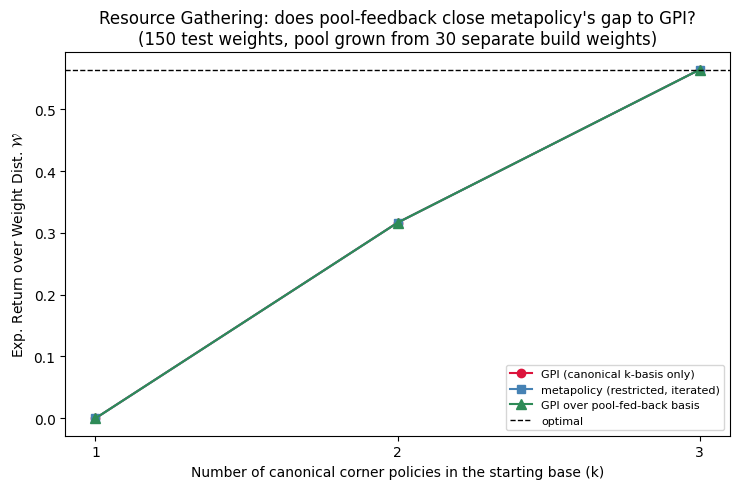

  k    GPI gap   metapolicy gap   pooled gap   % of metapolicy-GPI gap closed
  1     0.5641           0.5641       0.5641                             0.0%
  2     0.2476           0.2476       0.2476                             0.0%
  3     0.0000           0.0000       0.0000                             nan%

is pool-feedback actually cheap here too? (summed across all k)
restricted PI + gap check (baseline cost, shared)                :     1.04s  ( 93.6%)
meta_policy_sf linear solve (needed for ANY certify check anyway):     0.02s  (  1.4%)
extend to full table + append to pool (the ONLY new cost)        :     0.06s  (  5.0%)
total                                                            :     1.11s

incremental pool-feedback cost per policy actually added to the pool: 1.84 ms


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, gpi_curve, marker="o", ms=6, color="crimson", label="GPI (canonical k-basis only)")
ax.plot(ks, metapolicy_curve, marker="s", ms=6, color="steelblue", label="metapolicy (restricted, iterated)")
ax.plot(ks, pooled_curve, marker="^", ms=7, color="seagreen", label="GPI over pool-fed-back basis")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of canonical corner policies in the starting base (k)")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title(f"Resource Gathering: does pool-feedback close metapolicy's gap to GPI?\n"
             f"({N_TEST_WEIGHTS} test weights, pool grown from {N_BUILD_WEIGHTS} separate build weights)")
ax.set_xticks(ks)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

gap_metapolicy = [optimal_mean - v for v in metapolicy_curve]
gap_gpi = [optimal_mean - v for v in gpi_curve]
gap_pooled = [optimal_mean - v for v in pooled_curve]
closed_frac = [(gm - gp) / gm if gm > 1e-9 else float("nan") for gm, gp in zip(gap_metapolicy, gap_pooled)]

print(f"{'k':>3} {'GPI gap':>10} {'metapolicy gap':>16} {'pooled gap':>12} {'% of metapolicy-GPI gap closed':>32}")
for k, gm, gg, gp, cf in zip(ks, gap_metapolicy, gap_gpi, gap_pooled, closed_frac):
    print(f"{k:>3} {gg:>10.4f} {gm:>16.4f} {gp:>12.4f} {100*cf:>31.1f}%")

sep = "=" * 70
print(f"\n{sep}")
print("is pool-feedback actually cheap here too? (summed across all k)")
print(sep)
total_timing = {key: sum(t[key] for t in pool_timing_by_k) for key in pool_timing_by_k[0]}
total_added = sum(s["n_added"] for s in pool_stats_by_k)
total_t = sum(total_timing.values())
labels = {
    "t_restricted_pi": "restricted PI + gap check (baseline cost, shared)",
    "t_meta_sf_solve": "meta_policy_sf linear solve (needed for ANY certify check anyway)",
    "t_pool_feedback": "extend to full table + append to pool (the ONLY new cost)",
}
for key, v in total_timing.items():
    print(f"{labels[key]:65s}: {v:8.2f}s  ({100*v/total_t:5.1f}%)")
print(f"{'total':65s}: {total_t:8.2f}s")
if total_added > 0:
    print(f"\nincremental pool-feedback cost per policy actually added to the pool: "
          f"{1000*total_timing['t_pool_feedback']/total_added:.2f} ms")